# PS4 — Statistical Machine Translation: English → German (News / Media)
**AIML ZG521 NLP Applications · Assignment 2 · Part 1 (Programming)**

| Problem Statement | Group | Student name | Student ID |
|---|---|---|---|
| PS 4 | `<Group No>` | `<Member 1 name>` | `<ID>` |
| | | `<Member 2 name>` | `<ID>` |

### Problem statement
A news agency wants to translate wire stories and headlines from **English to German** to syndicate content to
European partners. We build (1) IBM Model 1 word alignment from scratch, (2) a phrase-based SMT system with an
n-gram language model and our own decoder, and (3) compare it against a pretrained neural MT model, evaluating
BLEU, adequacy, fluency, OOV handling, latency and robustness on the domain's stress-test focus (headlines with
dropped articles/verbs, long German compounds, named entities and quotations, date and place expressions).

### Scope of this notebook (Member 1 track)
| Section | Content |
|---|---|
| 0 | Configuration (shared with Member 2) |
| A | Corpus collection, cleaning, tokenization, split, corpus analysis → writes `data/` |
| E-data | 15-sentence evaluation set and robustness stress set (with German references) |
| D | Pretrained NMT (`Helsinki-NLP/opus-mt-en-de`) on the same test data; SMT-vs-NMT table and charts |
| Ref | References |

Parts B (IBM Model 1), C (phrase-based SMT) and the from-scratch BLEU of Part E are implemented in Member 2's
notebook and merged into the final submission. No API keys or tokens are used anywhere.

## 0. Configuration

In [1]:
import os, re, json, time, random, unicodedata, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sacremoses import MosesTokenizer
import sacrebleu

warnings.filterwarnings('ignore')
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
os.environ['HF_HUB_VERBOSITY'] = 'error'      # public model/dataset only: no HF token needed or used

# Shared configuration -- Member 2 uses the same values.
CONFIG = dict(
    SEED=42,
    POOL_SIZE=40_000,          # random pool drawn from the cleaned corpus before length filtering
    N_TRAIN=10_000, N_TEST=500, N_LM_HELDOUT=500,
    MIN_LEN=1, MAX_LEN=30,     # tokens, applied to both sides
    MAX_LEN_RATIO=2.0,         # max(len_en, len_de) / min(len_en, len_de)
    EM_ITERS=10, MAX_PHRASE_LEN=4, LM_ORDER=3, BEAMS=[1, 2, 5, 10],   # used by Parts B/C
    NMT_MODEL='Helsinki-NLP/opus-mt-en-de', NMT_BEAMS=4, NMT_BATCH=16,
)
SEED = CONFIG['SEED']
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd()
DATA, OUT = ROOT / 'data', ROOT / 'outputs'
FIG = OUT / 'figures'
for d in (DATA, OUT, FIG):
    d.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 110)
CONFIG

{'SEED': 42,
 'POOL_SIZE': 40000,
 'N_TRAIN': 10000,
 'N_TEST': 500,
 'N_LM_HELDOUT': 500,
 'MIN_LEN': 1,
 'MAX_LEN': 30,
 'MAX_LEN_RATIO': 2.0,
 'EM_ITERS': 10,
 'MAX_PHRASE_LEN': 4,
 'LM_ORDER': 3,
 'BEAMS': [1, 2, 5, 10],
 'NMT_MODEL': 'Helsinki-NLP/opus-mt-en-de',
 'NMT_BEAMS': 4,
 'NMT_BATCH': 16}

## Part A — Corpus collection, preprocessing and analysis

### A.1 Business scenario and target users
- **Scenario.** A news agency publishes English wire copy (breaking news, headlines, business and political
  reporting) and syndicates it to partner outlets in Germany, Austria and Switzerland. Translation must be fast
  (wire speed), faithful on facts (names, numbers, dates, places, quotations) and fluent enough for light
  post-editing.
- **Target users.** (i) Desk editors / post-editors at the agency who review machine output before release;
  (ii) German-language partner newsrooms consuming the feed; (iii) indirectly, their readers.
- **Implication for MT.** Errors on named entities, numbers and negation are far more costly than stylistic
  imperfections; headlines use a telegraphic register (dropped articles and verbs) that general corpora rarely
  contain.

### A.2 Corpus source
We use the **News Commentary** English–German parallel corpus (WMT training data, distributed via OPUS and
the Hugging Face hub as `Helsinki-NLP/news_commentary`, config `de-en`; ~223k sentence pairs; Tiedemann 2012).
It is the closest freely available match to the news domain among the suggested corpora: it contains
political and economic commentary (Project Syndicate) with article titles. **Europarl** was considered but
rejected as the primary source because parliamentary speech is a larger domain mismatch for wire news.
We sample a 10,000-pair training set (within the required 5k–20k) plus 500 held-out test pairs and 500
held-out German sentences for language-model perplexity.

In [2]:
from datasets import load_dataset

nc = load_dataset('Helsinki-NLP/news_commentary', 'de-en', split='train')
raw = pd.DataFrame([{'en': t['en'], 'de': t['de']} for t in nc['translation']])
print(f'News Commentary de-en: {len(raw):,} sentence pairs')
raw.sample(5, random_state=SEED)

News Commentary de-en: 223,153 sentence pairs


,en,de
158208,"This same lack of confidence is behind the potentially explosive situations in Algeria, Tunisia, and even ...","Derselbe Mangel an Selbstvertrauen ist die Grundlage für die potenziell explosive Lage in Algerien, Tunesi..."
192948,"For example, the presence of mirror neurons in Broca's region suggests that human language co-evolved with...","Zum Beispiel deutet das Vorhandensein von Spiegelneuronen in der Broca Region daraufhin, dass sich die men..."
53244,Alternative approaches are being tested and must be carefully reviewed.,Alternative Ansätze werden getestet und müssen sorgfältig überprüft werden.
40766,Back to Socialism,Zurück zum Sozialismus
58241,The goal is not to absorb shocks but to reduce income gaps across regions.,"Das Ziel besteht hier nicht darin, Erschütterungen aufzufangen, sondern Einkommensdifferenzen zwischen den..."


### A.3 Cleaning, normalization and tokenization
Pipeline (each step's effect is shown in the table below):
1. **Normalization** — Unicode NFC, collapse whitespace (kept with original casing as the *raw* text used by
   NMT and sacreBLEU).
2. **Cleaning** — drop pairs with an empty side, segments without letters, untranslated pairs (EN == DE) and
   duplicate English sources (prevents train/test leakage of repeated titles).
3. **Sampling** — a seeded random pool of 40,000 pairs (tokenizing all 223k is unnecessary for a 10k sample).
4. **Tokenization** — typographic quotes/dashes mapped to ASCII (German „…“ and English “…” become the same
   token), Moses tokenizer with language-specific rules (`sacremoses`, `en`/`de`), then lowercasing.
   German compounds are deliberately *not* split — this is one of the stress-test phenomena.
5. **Length filtering** — 1–30 tokens on both sides and length ratio ≤ 2 (removes misaligned pairs and keeps
   IBM Model 1 EM tractable, as its cost grows with |e|·|f| per sentence pair).

`preprocess(text, lang)` is the single tokenization function shared with Member 2 (Parts B, C, E).

In [3]:
QUOTE_MAP = str.maketrans({'„': '"', '“': '"', '”': '"', '«': '"', '»': '"',
                           '‚': "'", '‘': "'", '’': "'", '–': '-', '—': '-'})
_MOSES = {'en': MosesTokenizer(lang='en'), 'de': MosesTokenizer(lang='de')}

def normalize(text):
    """Unicode NFC + collapsed whitespace; casing and punctuation are kept (raw text)."""
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFC', text)).strip()

def preprocess(text, lang):
    """normalize -> ASCII quotes/dashes -> Moses tokenization -> lowercase. Returns a list of tokens."""
    text = normalize(text).translate(QUOTE_MAP)
    return [tok.lower() for tok in _MOSES[lang].tokenize(text, escape=False)]

print(preprocess('„Wir werden nicht nachgeben“, sagte Scholz am 3. Oktober in Berlin.', 'de'))
print(preprocess("The Fed's “dovish” turn won't last, analysts say.", 'en'))

['"', 'wir', 'werden', 'nicht', 'nachgeben', '"', ',', 'sagte', 'scholz', 'am', '3.', 'oktober', 'in', 'berlin', '.']
['the', 'fed', "'s", '"', 'dovish', '"', 'turn', 'won', "'t", 'last', ',', 'analysts', 'say', '.']


In [4]:
C = CONFIG
steps = [('raw pairs', len(raw))]

df = pd.DataFrame({'en': raw.en.map(normalize), 'de': raw.de.map(normalize)})
df = df[(df.en != '') & (df.de != '')];                                       steps.append(('drop empty side', len(df)))
df = df[df.en.str.contains('[A-Za-z]') & df.de.str.contains('[A-Za-zÄÖÜäöüß]')]; steps.append(('drop segments without letters', len(df)))
df = df[df.en.str.lower() != df.de.str.lower()];                              steps.append(('drop untranslated (EN == DE)', len(df)))
df = df.drop_duplicates(subset='en');                                         steps.append(('drop duplicate English sources', len(df)))

pool = df.sample(n=C['POOL_SIZE'], random_state=SEED).copy();                 steps.append(('seeded random pool', len(pool)))
pool['en_tok'] = pool.en.map(lambda s: preprocess(s, 'en'))
pool['de_tok'] = pool.de.map(lambda s: preprocess(s, 'de'))
pool['len_en'], pool['len_de'] = pool.en_tok.map(len), pool.de_tok.map(len)

keep = pool[pool.len_en.between(C['MIN_LEN'], C['MAX_LEN']) & pool.len_de.between(C['MIN_LEN'], C['MAX_LEN'])]
steps.append((f"length {C['MIN_LEN']}-{C['MAX_LEN']} tokens (both sides)", len(keep)))
ratio = keep[['len_en', 'len_de']].max(axis=1) / keep[['len_en', 'len_de']].min(axis=1)
keep = keep[ratio <= C['MAX_LEN_RATIO']];                                     steps.append((f"length ratio <= {C['MAX_LEN_RATIO']}", len(keep)))

pd.DataFrame(steps, columns=['step', 'pairs remaining'])

,step,pairs remaining
0,raw pairs,223153
1,drop empty side,223153
2,drop segments without letters,221705
3,drop untranslated (EN == DE),221567
4,drop duplicate English sources,220982
5,seeded random pool,40000
6,length 1-30 tokens (both sides),26134
7,length ratio <= 2.0,26049


### A.4 Train / test / LM-held-out split and export
The filtered pool is shuffled once with the fixed seed and cut into disjoint sets. Files are written to
`data/` in the format agreed with Member 2 (UTF-8, one sentence per line, EN/DE line-aligned).

In [5]:
keep = keep.sample(frac=1, random_state=SEED).reset_index(drop=True)
n_te, n_lm, n_tr = C['N_TEST'], C['N_LM_HELDOUT'], C['N_TRAIN']
test  = keep.iloc[:n_te].reset_index(drop=True)
lm_ho = keep.iloc[n_te:n_te + n_lm].reset_index(drop=True)
train = keep.iloc[n_te + n_lm:n_te + n_lm + n_tr].reset_index(drop=True)
assert len(train) == n_tr and len(test) == n_te and len(lm_ho) == n_lm
assert not set(train.en) & set(test.en), 'train/test overlap'

def write_lines(path, lines):
    path.write_text('\n'.join(lines) + '\n', encoding='utf-8')

for name, part in [('train', train), ('test', test)]:
    write_lines(DATA / f'{name}.tok.en', [' '.join(t) for t in part.en_tok])
    write_lines(DATA / f'{name}.tok.de', [' '.join(t) for t in part.de_tok])
write_lines(DATA / 'test.raw.en', test.en.tolist())
write_lines(DATA / 'test.raw.de', test.de.tolist())
write_lines(DATA / 'lm_heldout.tok.de', [' '.join(t) for t in lm_ho.de_tok])

for f in sorted(DATA.glob('*.??')):
    print(f'{f.name:22s} {sum(1 for _ in f.open(encoding="utf-8")):>6,} lines')

lm_heldout.tok.de         500 lines
README.md                  19 lines
test.raw.de               500 lines
test.raw.en               500 lines
test.tok.de               500 lines
test.tok.en               500 lines
train.tok.de           10,000 lines
train.tok.en           10,000 lines


### A.5 Corpus analysis

In [6]:
train_vocab = {l: Counter(t for s in train[f'{l}_tok'] for t in s) for l in ('en', 'de')}

def corpus_stats(lang):
    v = train_vocab[lang]
    n_tok = sum(v.values())
    lens = train[f'len_{lang}']
    test_toks = [t for s in test[f'{lang}_tok'] for t in s]
    oov = [t for t in test_toks if t not in v]
    return {
        'sentences (train)': len(train),
        'tokens (train)': n_tok,
        'vocabulary size (types)': len(v),
        'type/token ratio': round(len(v) / n_tok, 4),
        'singleton types (%)': round(100 * sum(c == 1 for c in v.values()) / len(v), 1),
        'avg sentence length': round(lens.mean(), 2),
        'median / max length': f'{int(lens.median())} / {lens.max()}',
        'test OOV token rate (%)': round(100 * len(oov) / len(test_toks), 2),
        'test OOV types': len(set(oov)),
    }

stats = pd.DataFrame({'English': corpus_stats('en'), 'German': corpus_stats('de')})
stats

,English,German
sentences (train),10000,10000
tokens (train),178274,179687
vocabulary size (types),15192,23197
type/token ratio,0.0852,0.1291
singleton types (%),48.3,59.6
avg sentence length,17.83,17.97
median / max length,18 / 30,18 / 30
test OOV token rate (%),3.93,7.49
test OOV types,352,671


In [7]:
def is_headline(s):
    return not s.rstrip().endswith(('.', '?', '!', '"', '“', '”', ':'))

head_share = 100 * train.en.map(is_headline).mean()
de_long_compounds = [w for w in train_vocab['de'] if w.isalpha() and len(w) >= 15]
print(f'Average DE/EN length ratio        : {(train.len_de / train.len_en).mean():.3f}')
print(f'Headline-like segments (train, EN): {head_share:.1f}%  (no sentence-final punctuation)')
print(f'German types with >= 15 letters   : {len(de_long_compounds):,} '
      f'({100 * len(de_long_compounds) / len(train_vocab["de"]):.1f}% of DE vocabulary)')
print('Examples:', ', '.join(sorted(de_long_compounds, key=len, reverse=True)[:8]))
print('Most frequent EN:', [w for w, _ in train_vocab['en'].most_common(15)])
print('Most frequent DE:', [w for w, _ in train_vocab['de'].most_common(15)])

Average DE/EN length ratio        : 1.022
Headline-like segments (train, EN): 4.7%  (no sentence-final punctuation)
German types with >= 15 letters   : 3,401 (14.7% of DE vocabulary)
Examples: telekommunikationsgesellschaften, leistungsbilanzungleichgewichte, spitzenrefinanzierungsfazilität, handelsliberalisierungsabkommen, fremdwährungsverbindlichkeiten, finanzdienstleistungsindustrie, nichtregierungsorganisationen, energieversorgungsunternehmen
Most frequent EN: ['the', '.', ',', 'of', 'to', 'and', 'in', 'a', 'is', 'that', "'s", 'for', 'it', 'be', 'are']
Most frequent DE: ['.', ',', 'die', 'der', 'und', 'in', 'zu', 'ist', 'den', 'das', 'eine', 'von', 'sich', 'nicht', 'es']


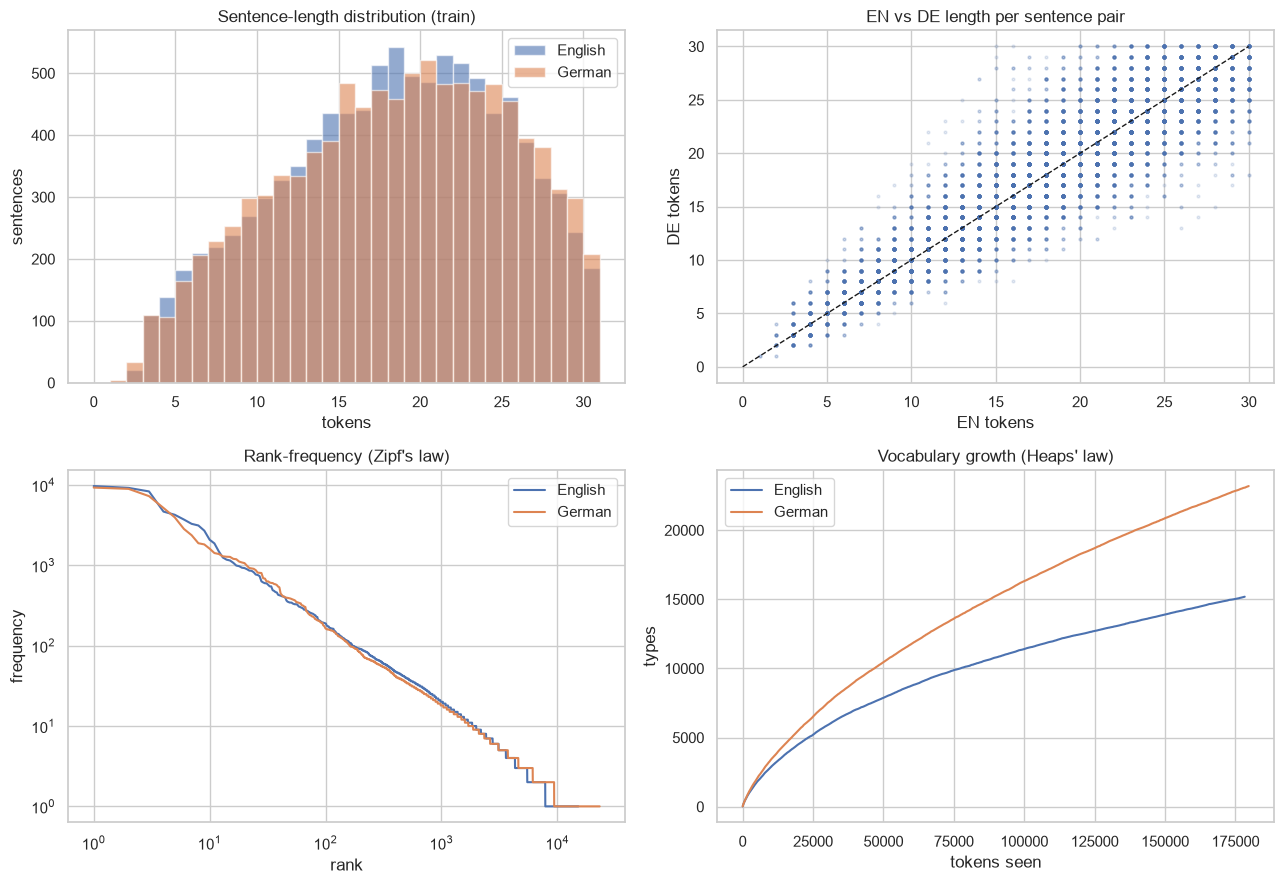

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
bins = np.arange(0, C['MAX_LEN'] + 2)
ax[0, 0].hist(train.len_en, bins=bins, alpha=.6, label='English')
ax[0, 0].hist(train.len_de, bins=bins, alpha=.6, label='German')
ax[0, 0].set(title='Sentence-length distribution (train)', xlabel='tokens', ylabel='sentences'); ax[0, 0].legend()

ax[0, 1].scatter(train.len_en, train.len_de, s=4, alpha=.15)
ax[0, 1].plot([0, 30], [0, 30], 'k--', lw=1)
ax[0, 1].set(title='EN vs DE length per sentence pair', xlabel='EN tokens', ylabel='DE tokens')

for lang, label in (('en', 'English'), ('de', 'German')):
    freqs = np.array(sorted(train_vocab[lang].values(), reverse=True))
    ax[1, 0].loglog(np.arange(1, len(freqs) + 1), freqs, label=label)
    seen, growth, n = set(), [], 0
    for s in train[f'{lang}_tok']:
        seen.update(s); n += len(s); growth.append((n, len(seen)))
    g = np.array(growth); ax[1, 1].plot(g[:, 0], g[:, 1], label=label)
ax[1, 0].set(title="Rank-frequency (Zipf's law)", xlabel='rank', ylabel='frequency'); ax[1, 0].legend()
ax[1, 1].set(title='Vocabulary growth (Heaps\' law)', xlabel='tokens seen', ylabel='types'); ax[1, 1].legend()
plt.tight_layout(); plt.savefig(FIG / 'A_corpus_analysis.png', dpi=120); plt.show()

### A.6 Observations, domain match and limitations
- **Size after cleaning.** 223,153 raw pairs → 220,982 after cleaning; from the 40k pool, 26,049 pairs (65%)
  pass the length filters, from which 10,000 train / 500 test / 500 LM-held-out are drawn.
- **German is lexically much sparser.** With almost identical token counts (~178k EN vs ~180k DE), German has
  **1.5× more types** (≈23.2k vs ≈15.2k), a higher type/token ratio (0.129 vs 0.085) and ~60% singleton types.
  Inflection (case, gender, number) and compounding split the probability mass, so many German words are seen
  once and IBM Model 1 / phrase-table estimates for them will be unreliable.
- **Compounds.** About 15% of German types have ≥ 15 letters (e.g. *leistungsbilanzungleichgewichte*,
  *nichtregierungsorganisationen*). Each aligns to several English words — a one-to-many pattern that IBM
  Model 1 cannot express (no fertility) and that phrase extraction only partially recovers.
- **OOV.** About 3.9% of English and 7.5% of German test tokens are unseen in training, and **233 of 500 test
  sentences contain at least one English OOV**, which a word/phrase-based system can only copy or drop.
  The vocabulary-growth curve has not flattened at 10k pairs, so more data would keep reducing OOV.
- **Length.** Average lengths are ~18 tokens on both sides (DE/EN ratio ≈ 1.02), indicating clean
  sentence alignment.
- **Domain match / mismatch.** News Commentary is *opinion and analysis* on economics and politics, not wire
  news: long analytical sentences, only ~5% headline-like segments, and little event vocabulary (police,
  storms, strikes, dates). We therefore expect the SMT system to handle economic/political terminology
  reasonably and to struggle on telegraphic headlines and breaking-news reporting — exactly the PS4 stress
  focus. A 10k-pair corpus is also tiny compared with the millions of pairs behind production SMT/NMT, so
  absolute SMT quality will be low; the pretrained NMT model has seen far more (and partly overlapping) data.
- **Limitations.** (i) Commentary register rather than wire copy; (ii) sentences longer than 30 tokens are
  excluded, although wire stories often contain long sentences; (iii) lowercasing removes German noun
  capitalization and named-entity cues; (iv) residual misalignments in the crawled corpus; (v) a random
  10k sample rather than the full corpus, chosen to keep from-scratch EM tractable.

In [9]:
readme = f'''# data/ — PS4 EN→DE parallel data (generated by A_D_member1.ipynb)

Source: News Commentary EN–DE (WMT training data), loaded from the Hugging Face hub
`Helsinki-NLP/news_commentary` (config `de-en`, {len(raw):,} pairs); also distributed via OPUS
(https://opus.nlpl.eu/datasets/News-Commentary). Licence: see the OPUS/WMT corpus page (research use).
Citation: J. Tiedemann (2012), Parallel Data, Tools and Interfaces in OPUS, LREC.

Pipeline: NFC + whitespace normalization; drop empty / letter-less / untranslated pairs; dedupe English side;
seeded pool of {C["POOL_SIZE"]:,}; ASCII quotes/dashes; Moses tokenizer (sacremoses, en/de, escape=False);
lowercase; keep {C["MIN_LEN"]}-{C["MAX_LEN"]} tokens per side and length ratio <= {C["MAX_LEN_RATIO"]}; seed {SEED}.

| file | lines | content |
|---|---|---|
| train.tok.en / train.tok.de | {len(train):,} | tokenized, lowercased training pairs |
| test.tok.en / test.tok.de | {len(test):,} | held-out pairs, same preprocessing |
| test.raw.en / test.raw.de | {len(test):,} | same test pairs, original casing, untokenized (NMT input, sacreBLEU refs) |
| lm_heldout.tok.de | {len(lm_ho):,} | German-only held-out sentences for LM perplexity |
| eval_set.csv | see file | 15-sentence evaluation set (id, category, en, de_ref, source) |
| stress_set.csv | see file | robustness stress set (id, phenomenon, en, de_ref, news_focus) |
'''
(DATA / 'README.md').write_text(readme, encoding='utf-8')
print('wrote data/README.md')

wrote data/README.md


## Evaluation set and robustness stress set (data for Part E)
**Evaluation set (15 sentences, 3 per category).** *Short*, *long* and *named entities & numbers* sentences
are drawn deterministically from the held-out test split, so their German references are the professional
corpus translations. *Domain terminology* (wire-news register) and *out-of-domain* sentences are authored by
the group with hand-written German references. NMT output is never used as a reference.

**Stress set.** Authored, news-flavoured tricky inputs covering negation, EN↔DE word-order divergence,
idioms/multi-word expressions, out-of-vocabulary words and ambiguous words, each tied to the PS4 stress-test
focus (headlines with dropped articles/verbs, long German compounds, named entities and quotations, date and
place expressions). References are hand-written and should be proof-read by a fluent German speaker.

In [10]:
used = set()
def pick(mask, k=3):
    rows = test[mask & ~test.index.isin(used)].head(k)
    used.update(rows.index)
    return rows

corpus_picks = {
    'short': pick(test.len_en.between(5, 9) & test.en.str.endswith('.')),
    'long': pick(test.len_en >= 26),
    'ne_numbers': pick(test.en.str.contains(r'\d') & test.en.str.contains(r'\s[A-Z][a-z]{2,}')),
}
authored = {
    'domain_term': [
        ('The spokesperson declined to comment on the allegations at a press conference.',
         'Der Sprecher lehnte es auf einer Pressekonferenz ab, sich zu den Vorwürfen zu äußern.'),
        ('According to preliminary results, the ruling coalition lost its majority in parliament.',
         'Nach vorläufigen Ergebnissen hat die Regierungskoalition ihre Mehrheit im Parlament verloren.'),
        ('The central bank raised interest rates by a quarter of a percentage point to curb inflation.',
         'Die Zentralbank erhöhte die Zinsen um einen Viertelprozentpunkt, um die Inflation einzudämmen.'),
    ],
    'out_of_domain': [
        ('Preheat the oven to 180 degrees and grease the baking tin.',
         'Heizen Sie den Backofen auf 180 Grad vor und fetten Sie die Backform ein.'),
        ('Restart your router and try connecting to the network again.',
         'Starten Sie Ihren Router neu und versuchen Sie erneut, eine Verbindung zum Netzwerk herzustellen.'),
        ('Hey, are we still meeting for coffee tomorrow afternoon?',
         'Hey, treffen wir uns morgen Nachmittag noch auf einen Kaffee?'),
    ],
}
rows = [(cat, r.en, r.de, 'corpus (test split)') for cat, part in corpus_picks.items() for r in part.itertuples()]
rows += [(cat, en, de, 'authored') for cat, pairs in authored.items() for en, de in pairs]
eval_set = pd.DataFrame(rows, columns=['category', 'en', 'de_ref', 'source'])
eval_set.insert(0, 'id', [f'E{i + 1:02d}' for i in range(len(eval_set))])
assert (eval_set.category.value_counts() >= 3).all() and len(eval_set) >= 15
eval_set.to_csv(DATA / 'eval_set.csv', index=False, encoding='utf-8')
eval_set

,id,category,en,de_ref,source
0,E01,short,Stock markets are rallying.,Die Aktienmärkte steigen.,corpus (test split)
1,E02,short,This can be done in creative ways.,Das kann auf kreative Weise erfolgen.,corpus (test split)
2,E03,short,Immanuel Kant described two types of politicians.,Immanuel Kant beschrieb zwei Arten von Politikern.,corpus (test split)
3,E04,long,A recent study by Andy Haldane and others at the Bank of England casts doubt on the prospect of a return t...,"Eine jüngere Studie von Andy Haldane und anderen von der Bank of England lässt Zweifel aufkommen, was die ...",corpus (test split)
4,E05,long,We count on China’s continued support for European and American efforts in making sure that Iran’s nuclear...,"Wir setzen auf Chinas dauerhafte Unterstützung der europäischen und amerikanischen Bemühungen, dafür zu so...",corpus (test split)
5,E06,long,At the top of the agenda should be ratification of improvements to a crucial nuclear security instrument –...,Ganz oben auf der Tagesordnung sollte die Verabschiedung von Verbesserungen eines entscheidenden Instrumen...,corpus (test split)
6,E07,ne_numbers,"The 10 new EU members do not have the same history as the Netherlands, Belgium, and Luxembourg.","Die 10 neuen EU-Mitglieder haben eine andere Geschichte als die Niederlande, Belgien und Luxemburg.",corpus (test split)
7,E08,ne_numbers,Putinism claimed victory after invading tiny Georgia in 2008.,"Putin verbuchte den Sieg für sich, nachdem er 2008 Truppen in das winzige Georgien einmarschieren ließ.",corpus (test split)
8,E09,ne_numbers,One such rule is the Maastricht Treaty’s cap on member states’ public debt at 60% of GDP.,"Eine dieser Regeln ist die Grenze von 60% des BIP, die im Maastricht-Vertrag für die Staatsschulden der Mi...",corpus (test split)
9,E10,domain_term,The spokesperson declined to comment on the allegations at a press conference.,"Der Sprecher lehnte es auf einer Pressekonferenz ab, sich zu den Vorwürfen zu äußern.",authored


In [11]:
stress_set = pd.DataFrame([
    ('negation', 'Police say the suspect was not armed and did not resist arrest.',
     'Die Polizei sagt, der Verdächtige sei nicht bewaffnet gewesen und habe sich der Festnahme nicht widersetzt.',
     'reported speech; double negation scope'),
    ('word_order', 'The chancellor said that the government would announce new sanctions against Russia on Monday.',
     'Der Kanzler sagte, dass die Regierung am Montag neue Sanktionen gegen Russland ankündigen werde.',
     'verb-final subordinate clause; date expression; named entity'),
    ('idiom_mwe', 'Opposition leaders say the reform has been kicked into the long grass.',
     'Oppositionsführer sagen, die Reform sei auf die lange Bank geschoben worden.',
     'idiom with a different German idiom'),
    ('oov_compound', 'Federal Constitutional Court halts speed-limit law',
     'Bundesverfassungsgericht stoppt Tempolimit-Gesetz',
     'headline with dropped articles; long German compound'),
    ('ambiguity', 'Union leaders call strike at Frankfurt airport',
     'Gewerkschaftsführer rufen zum Streik am Frankfurter Flughafen auf',
     'headline; union = Gewerkschaft (not EU); strike = Streik; place'),
    ('quotation_negation', '"We will not give in," Scholz told reporters in Berlin on 3 October.',
     '„Wir werden nicht nachgeben“, sagte Scholz am 3. Oktober vor Journalisten in Berlin.',
     'quotation; named entity; date; verb-second inversion after quote'),
    ('headline_dropped_verb', 'Storm leaves thousands without power in Bavaria',
     'Sturm lässt Tausende in Bayern ohne Strom',
     'headline register; place name (Bavaria -> Bayern)'),
    ('oov_neologism', 'Deepfake video of mayor sparks outrage',
     'Deepfake-Video des Bürgermeisters sorgt für Empörung',
     'OOV neologism; headline with dropped article'),
], columns=['phenomenon', 'en', 'de_ref', 'news_focus'])
stress_set.insert(0, 'id', [f'S{i + 1:02d}' for i in range(len(stress_set))])
stress_set.to_csv(DATA / 'stress_set.csv', index=False, encoding='utf-8')

src_vocab = train_vocab['en']
stress_set['oov_tokens'] = stress_set.en.map(lambda s: [t for t in preprocess(s, 'en') if t not in src_vocab])
stress_set

,id,phenomenon,en,de_ref,news_focus,oov_tokens
0,S01,negation,Police say the suspect was not armed and did not resist arrest.,"Die Polizei sagt, der Verdächtige sei nicht bewaffnet gewesen und habe sich der Festnahme nicht widersetzt.",reported speech; double negation scope,[]
1,S02,word_order,The chancellor said that the government would announce new sanctions against Russia on Monday.,"Der Kanzler sagte, dass die Regierung am Montag neue Sanktionen gegen Russland ankündigen werde.",verb-final subordinate clause; date expression; named entity,[]
2,S03,idiom_mwe,Opposition leaders say the reform has been kicked into the long grass.,"Oppositionsführer sagen, die Reform sei auf die lange Bank geschoben worden.",idiom with a different German idiom,[grass]
3,S04,oov_compound,Federal Constitutional Court halts speed-limit law,Bundesverfassungsgericht stoppt Tempolimit-Gesetz,headline with dropped articles; long German compound,"[halts, speed-limit]"
4,S05,ambiguity,Union leaders call strike at Frankfurt airport,Gewerkschaftsführer rufen zum Streik am Frankfurter Flughafen auf,headline; union = Gewerkschaft (not EU); strike = Streik; place,[]
5,S06,quotation_negation,"""We will not give in,"" Scholz told reporters in Berlin on 3 October.","„Wir werden nicht nachgeben“, sagte Scholz am 3. Oktober vor Journalisten in Berlin.",quotation; named entity; date; verb-second inversion after quote,[scholz]
6,S07,headline_dropped_verb,Storm leaves thousands without power in Bavaria,Sturm lässt Tausende in Bayern ohne Strom,headline register; place name (Bavaria -> Bayern),[bavaria]
7,S08,oov_neologism,Deepfake video of mayor sparks outrage,Deepfake-Video des Bürgermeisters sorgt für Empörung,OOV neologism; headline with dropped article,"[deepfake, sparks, outrage]"


## Part D — Neural MT comparison with a pretrained model
**Model.** `Helsinki-NLP/opus-mt-en-de` (MarianMT; Transformer encoder–decoder trained on OPUS data with
SentencePiece subwords; Tiedemann & Thottingal 2020). Used **as is** — no fine-tuning. Decoding: beam size 4,
batches of 16, CPU only.

**Caveat (data contamination).** OPUS-MT is trained on OPUS corpora, which include News Commentary, so some
of our test sentences may have been seen in NMT training. This can inflate NMT scores on the corpus test set;
the authored evaluation and stress sentences are not affected.

**Comparability.** The SMT system is trained on lowercased, tokenized text, so the primary BLEU comparison is
computed **case-insensitively** on detokenized output with sacreBLEU (13a tokenizer). Cased BLEU is also
reported for NMT.

In [12]:
import torch
import transformers
from transformers import MarianMTModel, MarianTokenizer

transformers.logging.set_verbosity_error()
torch.manual_seed(SEED)
nmt_tok = MarianTokenizer.from_pretrained(C['NMT_MODEL'])
nmt = MarianMTModel.from_pretrained(C['NMT_MODEL']).eval()
print(f"{C['NMT_MODEL']}: {sum(p.numel() for p in nmt.parameters()) / 1e6:.1f}M parameters, "
      f"torch {torch.__version__}, {torch.get_num_threads()} CPU threads")

def nmt_translate(sentences, batch_size=C['NMT_BATCH'], num_beams=C['NMT_BEAMS']):
    """Translate a list of raw English sentences. Returns (translations, total seconds)."""
    out, t0 = [], time.perf_counter()
    for i in range(0, len(sentences), batch_size):
        batch = nmt_tok(sentences[i:i + batch_size], return_tensors='pt', padding=True, truncation=True)
        with torch.inference_mode():
            gen = nmt.generate(**batch, num_beams=num_beams, max_new_tokens=256)
        out += nmt_tok.batch_decode(gen, skip_special_tokens=True)
    return out, time.perf_counter() - t0

nmt_out, batched_ms = {}, {}
for name, src in [('test', test.en.tolist()), ('eval', eval_set.en.tolist()), ('stress', stress_set.en.tolist())]:
    nmt_out[name], secs = nmt_translate(src)
    batched_ms[name] = 1000 * secs / len(src)
    write_lines(OUT / f'nmt_{name}.de', nmt_out[name])
    print(f'{name:6s}: {len(src):4d} sentences in {secs:6.1f}s  ({batched_ms[name]:.0f} ms/sentence, batched)')

# Production-style latency: one sentence per request.
single = []
for s in test.en.head(50):
    t0 = time.perf_counter(); nmt_translate([s], batch_size=1); single.append(time.perf_counter() - t0)
nmt_latency = {'batched_ms': round(batched_ms['test'], 1),
               'single_median_ms': round(1000 * float(np.median(single)), 1),
               'single_p95_ms': round(1000 * float(np.percentile(single, 95)), 1)}
nmt_latency

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Helsinki-NLP/opus-mt-en-de: 74.4M parameters, torch 2.15.0+cpu, 6 CPU threads


test  :  500 sentences in   75.9s  (152 ms/sentence, batched)


eval  :   15 sentences in    2.0s  (132 ms/sentence, batched)


stress:    8 sentences in    0.8s  (97 ms/sentence, batched)


{'batched_ms': 151.8, 'single_median_ms': 403.5, 'single_p95_ms': 607.9}

In [13]:
def bleu(hyps, refs, lowercase=True):
    return sacrebleu.corpus_bleu(hyps, [refs], lowercase=lowercase).score

def chrf(hyps, refs):
    return sacrebleu.corpus_chrf(hyps, [refs]).score

# OOV analysis: which test sentences contain source words never seen in SMT training?
test['oov'] = test.en_tok.map(lambda s: [t for t in s if t not in src_vocab])
has_oov = test.oov.map(bool)
print(f'Test sentences with >=1 OOV source token: {has_oov.sum()} / {len(test)}')

refs = test.de.tolist()
print(f"NMT test BLEU  (lowercased) {bleu(nmt_out['test'], refs):5.2f}")
print(f"NMT test BLEU  (cased)      {bleu(nmt_out['test'], refs, lowercase=False):5.2f}")
print(f"NMT test chrF               {chrf(nmt_out['test'], refs):5.2f}")
pd.DataFrame({'en': test.en, 'oov': test.oov.map(', '.join), 'nmt': nmt_out['test'], 'reference': test.de})[has_oov].head(5)

Test sentences with >=1 OOV source token: 233 / 500
NMT test BLEU  (lowercased) 28.75
NMT test BLEU  (cased)      28.28
NMT test chrF               59.71


,en,oov,nmt,reference
0,The dollar and the pound then shared international primacy in the 1920’s and 1930’s.,1920,Der Dollar und das Pfund teilten dann den internationalen Primat in den 1920er und 1930er Jahren.,In den 1920er und 1930er Jahren dann teilten sich der Dollar und das Pfund die internationale Vorrangstell...
1,"The 10 new EU members do not have the same history as the Netherlands, Belgium, and Luxembourg.",luxembourg,"Die zehn neuen EU-Mitglieder haben nicht die gleiche Geschichte wie die Niederlande, Belgien und Luxemburg.","Die 10 neuen EU-Mitglieder haben eine andere Geschichte als die Niederlande, Belgien und Luxemburg."
2,A recent study by Andy Haldane and others at the Bank of England casts doubt on the prospect of a return t...,"andy, haldane, ante",Eine kürzlich von Andy Haldane und anderen bei der Bank of England durchgeführte Studie wirft Zweifel an d...,"Eine jüngere Studie von Andy Haldane und anderen von der Bank of England lässt Zweifel aufkommen, was die ..."
11,That might well change if governments took simple steps like allocating more funding on a project basis an...,contests,"Das könnte sich auch ändern, wenn die Regierungen einfache Schritte wie die Zuweisung von mehr Finanzmitte...",Dies könnte sich durch einfache Regierungsmaßnahmen wie der Zuweisung auf Projektbasis oder dem Organisier...
12,"The United States has already passed legislation requiring public disclosure of payments to governments, t...",dodd-frank,"Die Vereinigten Staaten haben bereits Gesetze verabschiedet, die eine öffentliche Offenlegung von Zahlunge...","In den Vereinigten Staaten wurde mit dem Dodd-Frank-Gesetz im Jahr 2010 bereits ein Gesetz verabschiedet, ..."


### D.1 SMT vs NMT comparison
SMT outputs are produced by Member 2's pipeline (Part C) and dropped into `outputs/` as `smt_test.de`,
`smt_eval.de`, `smt_stress.de` (detokenized, one line per input) plus `smt_timing.json`
(`{"beam_width": int, "seconds_per_sentence": [...]}`). Until those files exist the SMT row shows *pending*.
Adequacy and fluency (1–5) are human judgements collected in `outputs/ratings.csv` (template created below).

In [14]:
def load_outputs(system):
    res = {}
    for name, n in [('test', len(test)), ('eval', len(eval_set)), ('stress', len(stress_set))]:
        p = OUT / f'{system}_{name}.de'
        lines = p.read_text(encoding='utf-8').splitlines() if p.exists() else None
        assert lines is None or len(lines) == n, f'{p.name}: {len(lines)} lines, expected {n}'
        res[name] = lines
    return res

smt_out = load_outputs('smt')
smt_timing = json.loads((OUT / 'smt_timing.json').read_text()) if (OUT / 'smt_timing.json').exists() else None

# Human-rating template (never overwritten once it exists, so manual scores are safe).
ratings_path = OUT / 'ratings.csv'
if not ratings_path.exists():
    sample = test.sample(25, random_state=SEED).index
    tmpl = pd.concat([
        pd.DataFrame({'set': 'test', 'id': [f'T{i:03d}' for i in sample], 'en': test.en[sample].values,
                      'de_ref': test.de[sample].values, 'nmt': [nmt_out['test'][i] for i in sample]}),
        pd.DataFrame({'set': 'eval', 'id': eval_set.id, 'en': eval_set.en, 'de_ref': eval_set.de_ref,
                      'nmt': nmt_out['eval']}),
    ], ignore_index=True)
    for col in ['smt', 'nmt_adequacy', 'nmt_fluency', 'smt_adequacy', 'smt_fluency']:
        tmpl[col] = None
    tmpl.to_csv(ratings_path, index=False, encoding='utf-8')
    print(f'created {ratings_path.name} with {len(tmpl)} rows to score (1-5)')
ratings = pd.read_csv(ratings_path)

def system_row(system, outs, latency_ms):
    if outs['test'] is None:
        return {'Approach': system}
    hyp = pd.Series(outs['test'])
    mean = lambda col: round(ratings[col].mean(), 2) if ratings[col].notna().any() else 'pending'
    prefix = 'smt' if 'SMT' in system else 'nmt'
    return {
        'Approach': system,
        'BLEU (test)': round(bleu(hyp.tolist(), refs), 2),
        'chrF (test)': round(chrf(hyp.tolist(), refs), 2),
        'BLEU (eval set)': round(bleu(outs['eval'], eval_set.de_ref.tolist()), 2),
        'Adequacy (1-5)': mean(f'{prefix}_adequacy'),
        'Fluency (1-5)': mean(f'{prefix}_fluency'),
        'OOV handling: BLEU on OOV sents': round(bleu(hyp[has_oov].tolist(), test.de[has_oov].tolist()), 2),
        'BLEU on OOV-free sents': round(bleu(hyp[~has_oov].tolist(), test.de[~has_oov].tolist()), 2),
        'Latency (ms/sentence)': round(latency_ms, 1) if latency_ms is not None else 'pending',
    }

smt_latency = 1000 * np.mean(smt_timing['seconds_per_sentence']) if smt_timing else None
comparison = pd.DataFrame([system_row('Phrase-Based SMT', smt_out, smt_latency),
                           system_row('Pretrained NMT (opus-mt-en-de)', nmt_out, nmt_latency['single_median_ms'])])
comparison.fillna('pending')

,Approach,BLEU (test),chrF (test),BLEU (eval set),Adequacy (1-5),Fluency (1-5),OOV handling: BLEU on OOV sents,BLEU on OOV-free sents,Latency (ms/sentence)
0,Phrase-Based SMT,pending,pending,pending,pending,pending,pending,pending,pending
1,Pretrained NMT (opus-mt-en-de),28.75,59.71,38.6,pending,pending,26.87,30.67,403.5


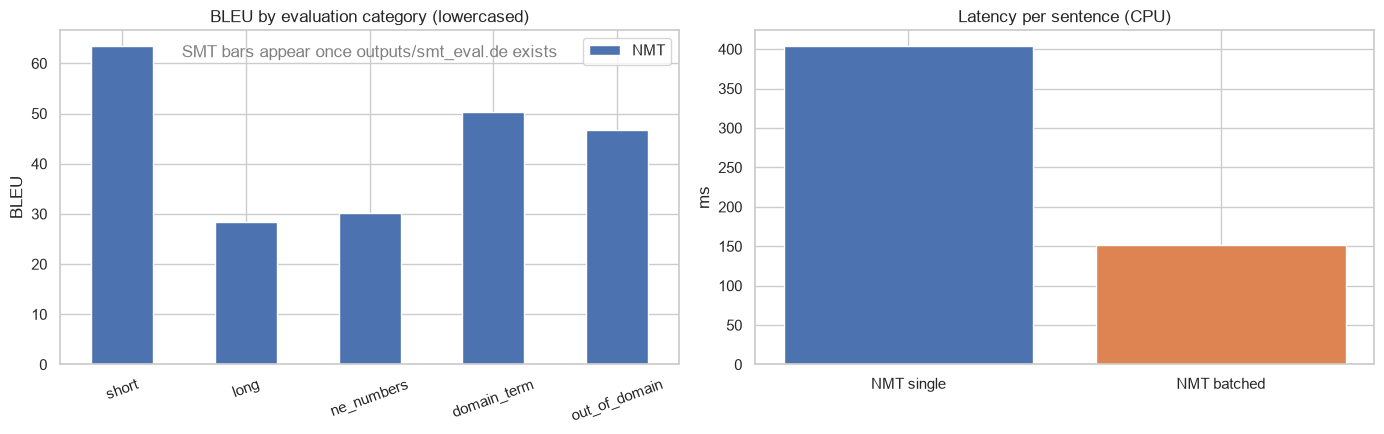

,NMT
short,63.38
long,28.38
ne_numbers,30.21
domain_term,50.28
out_of_domain,46.65


In [15]:
cats = eval_set.category.unique()
systems = {'NMT': nmt_out}
if smt_out['eval'] is not None:
    systems = {'SMT': smt_out, **systems}

per_cat = pd.DataFrame({
    s: [bleu([o['eval'][i] for i in eval_set.index[eval_set.category == c]],
             eval_set.de_ref[eval_set.category == c].tolist()) for c in cats]
    for s, o in systems.items()}, index=cats)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
per_cat.plot.bar(ax=ax[0], rot=20)
ax[0].set(title='BLEU by evaluation category (lowercased)', ylabel='BLEU')
if 'SMT' not in systems:
    ax[0].text(.5, .92, 'SMT bars appear once outputs/smt_eval.de exists', transform=ax[0].transAxes,
               ha='center', color='gray')

lat = {'NMT single': nmt_latency['single_median_ms'], 'NMT batched': nmt_latency['batched_ms']}
if smt_latency is not None:
    lat = {f"SMT (beam {smt_timing['beam_width']})": smt_latency, **lat}
ax[1].bar(lat.keys(), lat.values(), color=sns.color_palette()[:len(lat)])
ax[1].set(title='Latency per sentence (CPU)', ylabel='ms')
plt.tight_layout(); plt.savefig(FIG / 'D_comparison.png', dpi=120); plt.show()
per_cat.round(2)

In [16]:
# Stress-test outputs side by side, with an error-tagging template for Part E.
stress_view = stress_set[['id', 'phenomenon', 'en', 'de_ref']].assign(
    nmt=nmt_out['stress'], smt=smt_out['stress'] if smt_out['stress'] else 'pending')
tags_path = OUT / 'stress_error_tags.csv'
if not tags_path.exists():
    stress_view.assign(nmt_error='', smt_error='').to_csv(tags_path, index=False, encoding='utf-8')
    print(f'created {tags_path.name}; error categories: wrong lexical choice | reordering error | '
          'dropped word | hallucinated/inserted word | untranslated word | none')
stress_view

,id,phenomenon,en,de_ref,nmt,smt
0,S01,negation,Police say the suspect was not armed and did not resist arrest.,"Die Polizei sagt, der Verdächtige sei nicht bewaffnet gewesen und habe sich der Festnahme nicht widersetzt.",Laut Polizei war der Verdächtige nicht bewaffnet und widersetzte sich nicht der Verhaftung.,pending
1,S02,word_order,The chancellor said that the government would announce new sanctions against Russia on Monday.,"Der Kanzler sagte, dass die Regierung am Montag neue Sanktionen gegen Russland ankündigen werde.","Der Kanzler sagte, die Regierung werde am Montag neue Sanktionen gegen Russland ankündigen.",pending
2,S03,idiom_mwe,Opposition leaders say the reform has been kicked into the long grass.,"Oppositionsführer sagen, die Reform sei auf die lange Bank geschoben worden.","Oppositionsführer sagen, die Reform sei ins lange Gras getreten.",pending
3,S04,oov_compound,Federal Constitutional Court halts speed-limit law,Bundesverfassungsgericht stoppt Tempolimit-Gesetz,Bundesverfassungsgericht stoppt Geschwindigkeitsbegrenzungsrecht,pending
4,S05,ambiguity,Union leaders call strike at Frankfurt airport,Gewerkschaftsführer rufen zum Streik am Frankfurter Flughafen auf,EU-Führer rufen Streik am Flughafen Frankfurt an,pending
5,S06,quotation_negation,"""We will not give in,"" Scholz told reporters in Berlin on 3 October.","„Wir werden nicht nachgeben“, sagte Scholz am 3. Oktober vor Journalisten in Berlin.","""Wir werden nicht nachgeben"", sagte Scholz am 3. Oktober in Berlin.",pending
6,S07,headline_dropped_verb,Storm leaves thousands without power in Bavaria,Sturm lässt Tausende in Bayern ohne Strom,Sturm lässt Tausende ohne Macht in Bayern,pending
7,S08,oov_neologism,Deepfake video of mayor sparks outrage,Deepfake-Video des Bürgermeisters sorgt für Empörung,Deepfake Video von Bürgermeister Funken Empörung,pending


### D.2 Observations (NMT side; SMT columns are completed after merging Part C)
- **Quality.** opus-mt-en-de reaches about **28.8 BLEU (lowercased) / 59.7 chrF** on the 500-sentence test
  set. The score is probably inflated by training-data overlap with News Commentary (see the caveat above).
- **By category.** Short sentences score highest (≈63 BLEU) and long and *named entities & numbers* sentences
  lowest (≈28–30). Several low scores are reference paraphrases rather than errors (e.g. *10* → *zehn*,
  or the free corpus translation of E08). With 3 sentences per category these numbers are indicative only.
- **OOV handling.** BLEU drops only modestly on sentences with SMT-OOV words (≈26.9 vs ≈30.7). Subword
  units let the NMT copy or adapt names (*Haldane*, *Luxembourg → Luxemburg*, *Dodd-Frank*) instead of leaving
  them untranslated.
- **Latency.** About 0.4 s median per single sentence on a 6-thread CPU (p95 ≈ 0.6 s), and about 0.1–0.15 s per
  sentence when batched. This is acceptable for wire speed, but a GPU or batching would be needed at agency
  volume.
- **Stress test.** The NMT handles negation (S01), reported speech with subjunctive and date placement (S02,
  S06) and the long compound *Bundesverfassungsgericht* (S04) correctly. It fails on exactly the
  headline/ambiguity phenomena the scenario cares about:
  - *Union leaders → EU-Führer* and *call strike → Streik anrufen* (S05, wrong lexical choice ×2).
  - *power → Macht* instead of *Strom* (S07).
  - *sparks* read as a noun, giving *Funken* (S08: the dropped-verb headline is misparsed).
  - A literal idiom, *ins lange Gras getreten* (S03).
  - *vor Journalisten* dropped (S06, dropped word).

  These are tagged formally in `outputs/stress_error_tags.csv` together with the SMT output.

## References
**Data and models**
1. Tiedemann, J. (2012). Parallel Data, Tools and Interfaces in OPUS. *LREC 2012*. OPUS: https://opus.nlpl.eu/
2. News Commentary parallel corpus (WMT). https://opus.nlpl.eu/datasets/News-Commentary ; Hugging Face: https://huggingface.co/datasets/Helsinki-NLP/news_commentary
3. Koehn, P. (2005). Europarl: A Parallel Corpus for Statistical Machine Translation. *MT Summit X*. https://opus.nlpl.eu/datasets/Europarl (considered, not used as primary corpus)
4. Helsinki-NLP/opus-mt-en-de model card. https://huggingface.co/Helsinki-NLP/opus-mt-en-de
5. Tiedemann, J., & Thottingal, S. (2020). OPUS-MT — Building open translation services for the World. *EAMT 2020*. https://aclanthology.org/2020.eamt-1.61/
6. Tiedemann, J. (2020). The Tatoeba Translation Challenge — Realistic Data Sets for Low Resource and Multilingual MT. *WMT 2020*. https://aclanthology.org/2020.wmt-1.139/

**Methods**

7. Brown, P. F., Della Pietra, S. A., Della Pietra, V. J., & Mercer, R. L. (1993). The Mathematics of Statistical Machine Translation: Parameter Estimation. *Computational Linguistics* 19(2). https://aclanthology.org/J93-2003/
8. Och, F. J., & Ney, H. (2003). A Systematic Comparison of Various Statistical Alignment Models. *Computational Linguistics* 29(1). https://aclanthology.org/J03-1002/
9. Koehn, P., Och, F. J., & Marcu, D. (2003). Statistical Phrase-Based Translation. *NAACL 2003*. https://aclanthology.org/N03-1017/
10. Kneser, R., & Ney, H. (1995). Improved backing-off for M-gram language modeling. *ICASSP 1995*. doi:10.1109/ICASSP.1995.479394
11. Koehn, P., & Knight, K. (2003). Empirical Methods for Compound Splitting. *EACL 2003*. https://aclanthology.org/E03-1076/
12. Collins, M., Koehn, P., & Kučerová, I. (2005). Clause Restructuring for Statistical Machine Translation. *ACL 2005*. https://aclanthology.org/P05-1066/
13. Papineni, K., Roukos, S., Ward, T., & Zhu, W.-J. (2002). BLEU: a Method for Automatic Evaluation of Machine Translation. *ACL 2002*. https://aclanthology.org/P02-1040/
14. Post, M. (2018). A Call for Clarity in Reporting BLEU Scores. *WMT 2018*. https://aclanthology.org/W18-6319/
15. Koehn, P., & Knowles, R. (2017). Six Challenges for Neural Machine Translation. *Workshop on NMT*. https://aclanthology.org/W17-3204/
16. Collins, M. Phrase-Based Translation Models (lecture notes, Columbia University). http://www.cs.columbia.edu/~mcollins/pb.pdf
17. Harvard CS287, Lecture 8: Machine Translation. https://harvard-iacs.github.io/CS287/lectures/08_Machine_Translation.pdf

**Software:** sacremoses, sacreBLEU, Hugging Face `transformers` and `datasets`, PyTorch, NLTK, NumPy, pandas, Matplotlib, seaborn.